# Продажи автомобилей в Казахстане за январь–сентябрь 2019 года

### Бизнес-контекст
Вы — аналитик в автодилерском холдинге. Один из автоцентров холдинга, «Меркур Авто», хочет понять своё положение на рынке и выявить точки роста. Вам передали данные по всем продажам автомобилей в Казахстане за девять месяцев 2019 года.
Ваша задача — подготовить данные и провести анализ, который поможет менеджменту «Меркур Авто» оценить свою эффективность и принять стратегические решения.

### Проблема
Данные находятся в типичном для операционных систем состоянии: в них много нестандартных форматов, неявных ошибок и лишней информации. Из-за этого невозможно провести качественный анализ без тщательной предподготовки.

### Цели
— Техническая цель: довести датасет до состояния, пригодного для анализа. Создать скрипт его очистки для автоматизации обработки похожих данных в будущем.

— Аналитическая цель: провести разведочный анализ (EDA) всего рынка и дать оценку позиции и ключевым показателям эффективности автоцентра «Меркур Авто».

## 1. Загрузка и первичный осмотр данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

In [2]:
df = pd.read_csv('autokz2019.csv', 
                   sep=";", 
                   decimal=","
                  )

print("Размер:", df.shape)
display(df.head())
df.info()

Размер: (39966, 25)


,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",...,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,наличный,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
3,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,безналичный,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт
4,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,наличный,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс,D,Импорт


<class 'pandas.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Год                             39966 non-null  int64  
 1   Месяц                           39966 non-null  str    
 2   Компания                        39966 non-null  str    
 3   Бренд                           39966 non-null  str    
 4   Модель                          39966 non-null  str    
 5   Модификация                     36375 non-null  str    
 6   Год выпуска                     39465 non-null  str    
 7   Страна-производитель            39966 non-null  str    
 8   Вид топлива                     36826 non-null  str    
 9   Объём двиг, л,                  35708 non-null  str    
 10  Коробка передач                 36711 non-null  str    
 11  Тип привода                     35677 non-null  str    
 12  Сегмент                         33205 non-n

### Вывод 

- Данные поступили в формате 'csv'.
- В исходном файле 39 966 строк и 25 столбцов.
- В данных имеются пропуски. Особенно они заметны в «Форме расчета» (заполнено 14 038 строк), «Сегменте», «Типе клиента», а также в характеристиках автомобиля.
- «Количество», «Цена, USD» и «Продажа, USD» прочитались как числа; при этом «Год выпуска» и «Объём двиг, л,» пока имеют текстовый тип — их значения нужно изучить перед преобразованием.
- «Месяц» записан словами; позднее его потребуется перевести в номер месяца для создания даты продажи.

## 2. Подготовка данных

In [3]:
# Проверим, есть ли полностью пустые строки и точные дубликаты.
# Удалим их до удаления столбцов, чтобы не принять за дубликаты записи,
# которые различались в исходных данных. Результат сохраняем в data,
# а исходный датафрейм df оставляем без изменений.

print("Полностью пустых строк:", df.isna().all(axis=1).sum())
print("Точных совпадений:", df.duplicated().sum())
data = df.dropna(how="all").drop_duplicates().copy()
print("После удаления:", data.shape)
display(data.head(3))

Полностью пустых строк: 0
Точных совпадений: 18698
После удаления: (21268, 25)


,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",...,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",...,Юр. Лицо,наличный,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",...,Физ. Лицо,безналичный,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс,D,Импорт


### 2.1. Ненужные столбцы и английские имена

In [4]:
# Удалим поля, которые по заданию не будут участвовать в анализе.
# Затем дадим оставшимся столбцам короткие английские имена для дальнейшего кода.

unused_columns = [
    "Модификация", "Сегмент", "Тип клиента", "Форма расчета",
    "Локализация производства", "Наименование дилерского центра",
    "Сегментация Eng",
]
data = data.drop(columns=unused_columns)
data = data.rename(columns={
    "Год": "year", 
    "Месяц": "month", 
    "Компания": "company",
    "Бренд": "brand", 
    "Модель": "model", 
    "Год выпуска": "production_year",
    "Страна-производитель": "production_country", 
    "Вид топлива": "fuel_type",
    "Объём двиг, л,": "engine_volume_l", 
    "Коробка передач": "transmission",
    "Тип привода": "drive_type", 
    "Регион": "region", 
    "Область": "area",
    "Количество": "quantity", 
    "Цена, USD": "unit_price_usd",
    "Продажа, USD": "total_sales_usd", 
    "Сегментация 2013": "segment_2013",
    "Класс 2013": "class_2013",
})
display(data.head(3))

,year,month,company,brand,model,production_year,production_country,fuel_type,engine_volume_l,transmission,drive_type,region,quantity,unit_price_usd,total_sales_usd,area,segment_2013,class_2013
0,2019,Май,Mercur Auto,Audi,A3,2018,Германия,Бензин,"1,4",S-tronic,передний,Алматы,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс
1,2019,Август,Mercur Auto,Audi,A3,2018,Германия,Бензин,"1,4",S-tronic,передний,Алматы,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс
2,2019,Апрель,Mercur Auto,Audi,A4,2018,Германия,Бензин,"1,4",S-Tronic,FWD,Алматы,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс


### 2.2. Страны, топливо, привод и трансмиссия

In [5]:
# В данных один и тот же вид топлива, привода или коробки передач
# может быть записан по-разному. Ниже создаём функции,
# которые приводят такие записи к единым обозначениям.


# Вид топлива: заменяем полные названия короткими кодами.
# Например, «бензин» → F, «дизель» → D.
# Пропуски и непонятные значения оставляем пропусками.

def clean_fuel(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip().lower()
    if text == "бензин":
        return "F"
    if text == "дизель":
        return "D"
    if text in ("электро", "электричество"):
        return "E"
    if text == "гибрид":
        return "HYB"
    return pd.NA

# Тип привода: объединяем разные названия одного типа.
# Например, AWD, 4WD и «Полный» записываем одинаково — 4WD.
# Также приводим к одному виду обозначения переднего и заднего привода.

def clean_drive(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip().upper().replace(" ", "")
    text = text.replace("Х", "X")
    if text in {"4WD", "AWD", "4X4", "ПОЛНЫЙ", "QUATTRO", "4MOTION"}:
        return "4WD"
    if text in {"2WD", "2X2", "2X4", "4X2", "4X2.2"}:
        return "2WD"
    if text in {"FF", "FWD", "ПЕРЕДНИЙ", "ПЕРЕДНИЙ(FF)"}:
        return "FWD"
    if text in {"RWD", "ЗАДНИЙ"}:
        return "RWD"
    return pd.NA

# Коробка передач: сводим разные обозначения к двум категориям —
# «Автомат» и «Механика». Если по записи нельзя определить тип,
# оставляем пропуск, чтобы не приписать машине неверную коробку.

def clean_transmission(value):
    if pd.isna(value):
        return pd.NA
    original = str(value).upper().strip()
    if any(word in original for word in ("МЕХ", "МКП", "МТ")):
        return "Механика"
    if any(word in original for word in ("АКП", "АТ", "ВАРИАТОР")):
        return "Автомат"
    text = original
    # Убираем пробелы и различия похожих латинских/кириллических букв.
    text = text.replace("А", "A").replace("Т", "T").replace("М", "M")
    text = text.replace(" ", "")
    if text in {"0", "#Н/Д", "8", "4WD", "ПЕРЕДНИЙ", "TDI"}:
        return pd.NA
    if any(word in text for word in ("MT", "M/T")) or re.fullmatch(r"\d+M", text):
        return "Механика"
    if any(word in text for word in ("AT", "A/T", "CVT", "DSG", "DCT", "PDK", "TRONIC", "TIPTRONIC", "STEPTRONIC", "POWERSHIFT", "РЕДУКТОР", "AMT")) or re.fullmatch(r"\d+A", text):
        return "Автомат"
    return pd.NA


In [6]:
# Для упрощения работы с данными словарь переводит названия стран в трёхбуквенные коды ISO.

country_codes = {
    "Республика Казахстан": "KAZ", 
    "Российская Федерация": "RUS",
    "Япония": "JPN", 
    "Турция": "TUR", 
    "Таиланд": "THA", 
    "США": "USA",
    "Германия": "DEU", 
    "UK": "GBR", 
    "Китай": "CHN", 
    "Узбекистан": "UZB",
    "Австрия": "AUT", 
    "Швеция": "SWE", 
    "Корея": "KOR",
    "Нидерланды": "NLD", 
    "Испания": "ESP", 
    "Польша": "POL",
    "Бельгия": "BEL", 
    "Венгрия": "HUN", 
    "Белоруссия": "BLR",
}

# Теперь применяем замены к столбцам data.
# Для стран берём коды из словаря, а для остальных столбцов
# используем функции, которые написали в предыдущей ячейке.

data["production_country"] = data["production_country"].map(country_codes)
data["fuel_type"] = data["fuel_type"].map(clean_fuel)
data["drive_type"] = data["drive_type"].map(clean_drive)
data["transmission"] = data["transmission"].map(clean_transmission)


In [7]:
# После замены снова посчитаем категории и пропуски.

for column in ["production_country", "fuel_type", "drive_type", "transmission"]:
    print("\n", column)
    display(data[column].value_counts(dropna=False).head(25))



 production_country


production_country
KAZ    10453
RUS     6574
JPN     2559
TUR      449
THA      392
USA      257
DEU      252
GBR      179
AUT       33
UZB       30
CHN       22
KOR       16
SWE       16
NLD       12
ESP        9
POL        6
BEL        6
HUN        2
BLR        1
Name: count, dtype: int64


 fuel_type


fuel_type
F      18684
NaN     1917
D        653
HYB       10
E          4
Name: count, dtype: int64


 drive_type


drive_type
4WD    8779
FWD    4578
2WD    4325
NaN    2294
RWD    1292
Name: count, dtype: int64


 transmission


transmission
Автомат     13642
Механика     5705
NaN          1921
Name: count, dtype: int64

In [8]:
# Снова взглянем на таблицу.

display(data.head())
print(data.info())

,year,month,company,brand,model,production_year,production_country,fuel_type,engine_volume_l,transmission,drive_type,region,quantity,unit_price_usd,total_sales_usd,area,segment_2013,class_2013
0,2019,Май,Mercur Auto,Audi,A3,2018,DEU,F,"1,4",Автомат,FWD,Алматы,1.0,28115.00,28115.00,г.Алматы,Легковые автомобили,C класс
1,2019,Август,Mercur Auto,Audi,A3,2018,DEU,F,"1,4",Автомат,FWD,Алматы,1.0,32246.99,32246.99,г.Алматы,Легковые автомобили,C класс
2,2019,Апрель,Mercur Auto,Audi,A4,2018,DEU,F,"1,4",Автомат,FWD,Алматы,1.0,32000.00,32000.00,г.Алматы,Легковые автомобили,D класс
3,2019,Июль,Mercur Auto,Audi,A4,2018,DEU,F,"1,4",Автомат,FWD,Алматы,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс
4,2019,Июль,Mercur Auto,Audi,A4,2018,DEU,F,"1,4",Автомат,FWD,Алматы,1.0,31929.00,31929.00,г.Алматы,Легковые автомобили,D класс


<class 'pandas.DataFrame'>
Index: 21268 entries, 0 to 39951
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   year                21268 non-null  int64  
 1   month               21268 non-null  str    
 2   company             21268 non-null  str    
 3   brand               21268 non-null  str    
 4   model               21268 non-null  str    
 5   production_year     21035 non-null  str    
 6   production_country  21268 non-null  str    
 7   fuel_type           19351 non-null  str    
 8   engine_volume_l     18976 non-null  str    
 9   transmission        19347 non-null  str    
 10  drive_type          18974 non-null  str    
 11  region              21268 non-null  str    
 12  quantity            21262 non-null  float64
 13  unit_price_usd      21268 non-null  float64
 14  total_sales_usd     21268 non-null  float64
 15  area                21268 non-null  str    
 16  segment_2013        

### 2.3. Объём двигателя

In [9]:
# Сначала смотрим, как объём двигателя записан у Jaguar и Chevrolet Niva.
# У Jaguar ищем значения, которые могут обозначать не литры, а мощность.
# У Chevrolet Niva считаем, какие значения встречаются чаще всего:
# это поможет понять, какие записи похожи на ошибки.
# Пока данные не меняем — только изучаем исходные значения.

display(data.loc[data["brand"].eq("Jaguar"), ["model", "engine_volume_l"]].drop_duplicates().head(20))
display(data.loc[data["brand"].eq("Chevrolet") & data["model"].eq("Niva"), "engine_volume_l"].value_counts().head(20))


,model,engine_volume_l
15023,F-Pace,2
15038,F-Type,3
15039,XE,2
15040,XF,5
15041,XF,2
15042,XF,3
15044,XJ,3
15045,XJ,NaN
38858,E-PACE,2
38864,E-PACE,NaN


engine_volume_l
1,7     254
26,7      1
25,7      1
24,7      1
23,7      1
22,7      1
21,7      1
20,7      1
19,7      1
18,7      1
17,7      1
16,7      1
15,7      1
14,7      1
13,7      1
12,7      1
11,7      1
10,7      1
9,7       1
8,7       1
Name: count, dtype: int64

In [10]:
# Создаём функцию для обработки одного значения объёма двигателя.
# Она заменяет десятичную запятую точкой и извлекает число из записи,
# например из «1,6 L» получает 1.6.
# Если вместо литража записана мощность, ёмкость батареи или непонятный текст,
# функция возвращает пропуск.
# Для Chevrolet Niva явно ошибочные объёмы заменяем на 1.7 л:
# именно это значение преобладает в записях данной модели.
# Сейчас функция только создаётся — весь столбец пока не меняется.

def clean_engine(value, brand, model):
    if pd.isna(value):
        return float("nan")
    text = str(value).strip().upper().replace(",", ".")
    # У электрического Jaguar 400 Л.С. означает мощность, а не литраж.
    if "Л.С" in text or "KWH" in text or text in {"AT", "MT", "#Н/Д"}:
        return float("nan")
    match = re.match(r"^\s*(\d+(?:\.\d+)?)", text)
    if match is None:
        return float("nan")
    liters = float(match.group(1))
    # В этой выгрузке у Chevrolet Niva есть последовательность 2.7–26.7,
    # тогда как подавляющее большинство записей той же модели — 1.7 л.
    if brand == "Chevrolet" and model == "Niva" and liters != 1.7:
        return 1.7
    if liters <= 0:
        return float("nan")
    return liters


In [11]:
# Теперь обрабатываем каждую строку таблицы.
# Передаём функции не только запись объёма, но также бренд и модель:
# правило для Chevrolet Niva должно применяться только к этой модели.
# Полученные числовые значения записываем обратно в engine_volume_l.

cleaned_volumes = []

# Проходим по строкам датафрейма.
for index in data.index:
    volume = data.loc[index, "engine_volume_l"]
    brand = data.loc[index, "brand"]
    model = data.loc[index, "model"]

    cleaned_volume = clean_engine(volume, brand, model)
    cleaned_volumes.append(cleaned_volume)

# Когда все строки обработаны, заменяем исходный столбец новым.
data["engine_volume_l"] = cleaned_volumes


In [12]:
# У одной записи Volkswagen Polo указан неправдоподобный объём 8,7 л.
# По другим записям модели нельзя точно установить объём этой машины,
# поэтому заменяем сомнительное значение пропуском.

data.loc[
    (data["brand"] == "Volkswagen")
    & (data["model"] == "Polo")
    & (data["engine_volume_l"] == 8.7),
    "engine_volume_l"
] = float("nan")


# Проверяем получившиеся числовые значения.
display(data["engine_volume_l"].describe())

count    18941.000000
mean         2.293305
std          0.937965
min          1.200000
25%          1.600000
50%          2.000000
75%          2.700000
max         13.000000
Name: engine_volume_l, dtype: float64

### 2.4. Количество, цена и сумма продажи

In [13]:
# Количество, цену и общую сумму продажи переводим в числовой формат.
# Если какое-то значение не удастся прочитать как число, оно станет пропуском.

# В годе выпуска иногда стоит пробел внутри числа: например, «2 019».
# Убираем этот пробел, затем переводим год в целое число.
# Используем Int64, потому что в столбце есть пропущенные годы.

# После преобразования смотрим обычные значения и отдельно показываем
# возвраты и крупные заказы. Их пока не удаляем.

for column in ["quantity", "unit_price_usd", "total_sales_usd"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")
data["production_year"] = pd.to_numeric(
    data["production_year"].astype("string").str.replace("\u00a0", "", regex=False),
    errors="coerce",
).astype("Int64")

display(data[["quantity", "unit_price_usd", "total_sales_usd"]].describe())
display(data.loc[(data["quantity"] < 0) | (data["quantity"] >= 100), ["brand", "model", "quantity", "total_sales_usd"]])


,quantity,unit_price_usd,total_sales_usd
count,21262.000000,21268.000000,2.126800e+04
mean,1.653890,27994.540081,3.832893e+04
std,3.222347,21279.082963,6.697741e+04
min,-1.000000,7100.000000,-3.558825e+04
25%,1.000000,14886.298720,1.655944e+04
50%,1.000000,20700.000000,2.523592e+04
75%,1.000000,32380.850850,4.131110e+04
max,115.000000,328510.970600,3.778206e+06


,brand,model,quantity,total_sales_usd
16885,Lada,4x4,115.0,1035000.00
25555,Skoda,Octavia,100.0,1870000.00
25728,Skoda,Superb,-1.0,-35588.25


In [14]:
# Проверяем, сходится ли арифметика в строках:
# цена одной машины × количество машин = итоговая сумма продажи.
# Строки без количества проверить таким способом нельзя.
# Отдельно считаем, сколько таких строк осталось.

known = data["quantity"].notna()
diff = (data.loc[known, "total_sales_usd"] - data.loc[known, "quantity"] * data.loc[known, "unit_price_usd"]).abs()
print("Несовпадений более 1 цента:", (diff > 0.01).sum())
print("Неизвестно количество:", data["quantity"].isna().sum())


Несовпадений более 1 цента: 0
Неизвестно количество: 6


### 2.5. Дата и названия компаний

В исходных данных указан месяц продажи, но не указан день. По условию проекта для каждой записи создаём дату с последним календарным днём соответствующего месяца. Это условная дата для месячного учёта, а не фактический день продажи. Затем приводим к одному написанию названия одних и тех же компаний.

In [15]:
# Словарь связывает название месяца с его номером:
# «Январь» — 1, «Февраль» — 2 и так далее.

month_numbers = {
    "Январь": 1, "Февраль": 2, "Март": 3, "Апрель": 4,
    "Май": 5, "Июнь": 6, "Июль": 7, "Август": 8, "Сентябрь": 9,
    "Октябрь": 10, "Ноябрь": 11, "Декабрь": 12,
}
# Заменяем названия месяцев их номерами.
month = data["month"].map(month_numbers)

# Из года и номера месяца создаём дату.
# Сначала временно ставим первое число месяца, поскольку
# точный день продажи в исходном файле неизвестен.
data["sale_date"] = pd.to_datetime(
    {"year": data["year"], "month": month, "day": 1}, errors="coerce"
) + pd.offsets.MonthEnd(0) # переносим на последний день того же месяца

# Год и месяц отдельно больше не нужны: они уже вошли в sale_date.
data = data.drop(columns=["year", "month"])

# Убираем случайные пробелы в начале и конце названий компаний.
data["company"] = data["company"].astype("string").str.strip()

# Затем объединяем известные разные написания одной компании:
# например, Mercur Autos и Mercur Auto будут считаться одной компанией.
data["company"] = data["company"].replace({
    "Mercur Autos": "Mercur Auto",
    "Ravon Motors Kazakstan": "Равон Моторс Казахстан",
    "MMC RUS": "ММС Рус",
    "Автокапитал": "Autokapital",
    "Каспиан Моторс": "Caspian Motors",
})

# Приводим написание региона и области к виду,
# где каждое слово начинается с заглавной буквы.
data["region"] = data["region"].astype("string").str.title()
data["area"] = data["area"].astype("string").str.title()

# В конце проверяем даты и наиболее частые названия компаний
# после преобразований.
display(data["sale_date"].value_counts().sort_index())
display(data["company"].value_counts().head(20))


sale_date
2019-01-31    1840
2019-02-28    1866
2019-03-31    2178
2019-04-30    2626
2019-05-31    2636
2019-06-30    2545
2019-07-31    2620
2019-08-31    2484
2019-09-30    2473
Name: count, dtype: int64

company
Astana Motors                   5011
Toyota Motor Kazakhstan         4450
БИПЭК АВТО                      3599
Вираж                           2017
Renault Россия                  1193
Nissan Manufacturing RUS        1115
Allur Auto                       646
Mercur Auto                      387
Равон Моторс Казахстан           387
ММС Рус                          386
Subaru Kazakhstan                333
ТК КАМАЗ                         328
Автоцентр-Бавария                224
Лифан Моторс Рус                 137
Autokapital                      118
Автомир ГК                       110
Volkswagen Group Rus             100
СемАЗ                             91
Almaty Motors Premium             90
Hyundai Com Trans Kazakhstan      89
Name: count, dtype: int64[pyarrow]

### 2.6. Типы, пропуски и итоговый CSV

In [16]:
# Переводим пять столбцов с повторяющимися категориями
# в специальный тип pandas category.
# Это не меняет сами названия категорий: они уже были приведены
# к нужному виду на предыдущих шагах.

for column in ["fuel_type", "transmission", "drive_type", "segment_2013", "class_2013"]:
    data[column] = data[column].astype("category")

# Проверяем тип каждого столбца после преобразований.
display(data.dtypes)

# Считаем оставшиеся пропуски по всем столбцам.
# Сортировка показывает сначала столбцы с наибольшим числом пропусков.
display(data.isna().sum().sort_values(ascending=False))

# Анализируем первые строки итоговой таблицы перед сохранением.
display(data.head())


company                       string
brand                            str
model                            str
production_year                Int64
production_country               str
fuel_type                   category
engine_volume_l              float64
transmission                category
drive_type                  category
region                        string
quantity                     float64
unit_price_usd               float64
total_sales_usd              float64
area                          string
segment_2013                category
class_2013                  category
sale_date             datetime64[us]
dtype: object

engine_volume_l       2327
drive_type            2294
transmission          1921
fuel_type             1917
production_year        233
quantity                 6
unit_price_usd           0
class_2013               0
segment_2013             0
area                     0
total_sales_usd          0
company                  0
region                   0
brand                    0
production_country       0
model                    0
sale_date                0
dtype: int64

,company,brand,model,production_year,production_country,fuel_type,engine_volume_l,transmission,drive_type,region,quantity,unit_price_usd,total_sales_usd,area,segment_2013,class_2013,sale_date
0,Mercur Auto,Audi,A3,2018,DEU,F,1.4,Автомат,FWD,Алматы,1.0,28115.00,28115.00,Г.Алматы,Легковые автомобили,C класс,2019-05-31
1,Mercur Auto,Audi,A3,2018,DEU,F,1.4,Автомат,FWD,Алматы,1.0,32246.99,32246.99,Г.Алматы,Легковые автомобили,C класс,2019-08-31
2,Mercur Auto,Audi,A4,2018,DEU,F,1.4,Автомат,FWD,Алматы,1.0,32000.00,32000.00,Г.Алматы,Легковые автомобили,D класс,2019-04-30
3,Mercur Auto,Audi,A4,2018,DEU,F,1.4,Автомат,FWD,Алматы,1.0,31929.00,31929.00,Г.Алматы,Легковые автомобили,D класс,2019-07-31
4,Mercur Auto,Audi,A4,2018,DEU,F,1.4,Автомат,FWD,Алматы,1.0,31929.00,31929.00,Г.Алматы,Легковые автомобили,D класс,2019-07-31


In [17]:
# Сохраняем обработанный датафрейм в новый CSV рядом с исходным файлом.
# В имени добавляем _clean, чтобы не заменить исходный autokz2019.csv.

data.to_csv(
    'autokz2019_clean.csv', 
    sep=";", decimal=",", 
    index=False,
    encoding="utf-8-sig", 
    date_format="%Y-%m-%d",
)

# Открываем созданный файл, чтобы убедиться в его корректности.
saved = pd.read_csv(
    'autokz2019_clean.csv', 
    sep=";", 
    decimal=",", 
    parse_dates=["sale_date"])

print("Размер сохранённого CSV:", saved.shape)


Размер сохранённого CSV: (21268, 17)


### Вывод

- Исходная таблица содержала *39 966 строк и 25 столбцов*. Полностью пустых строк не обнаружено. Перед удалением лишних столбцов найдено *18 698 строк, полностью совпадающих по всем исходным полям*. После их удаления и исключения семи неиспользуемых столбцов в таблице осталось *21 268 строк и 17 столбцов*. Оставшиеся столбцы переименованы на английский язык.

- Значения категориальных признаков приведены к единому виду: страны производства обозначены трёхбуквенными кодами, виды топлива — кодами `F`, `D`, `E` и `HYB`, варианты написания типа привода объединены, а коробки передач сведены к категориям «Автомат» и «Механика». Значения, которые нельзя было уверенно распознать, оставлены пропусками.

- Столбец с объёмом двигателя преобразован в числовой формат: десятичные запятые заменены точками, а лишние обозначения убраны. Запись `400 Л.С.` у Jaguar не принята за объём двигателя, поскольку она обозначает мощность. Ошибочные значения у Chevrolet Niva исправлены на *1,7 л* на основании преобладающего значения для этой модели в исходных данных.

- Неправдоподобный объём Volkswagen Polo в значении 8,7 л. был заменён на NaN, поскольку его нельзя восстановить по имеющимся значениям.

- Количество автомобилей, цена и итоговая стоимость приведены к числовым типам. *Возврат с количеством −1* и *два крупных заказа от 100 автомобилей* сохранены: это возможные реальные операции, а не основание автоматически удалять строки. Для записей с известным количеством проверено соответствие итоговой стоимости произведению цены и количества; расхождений более одного цента не обнаружено. В шести строках количество остаётся неизвестным.

- Из года и месяца создан столбец `sale_date`. Поскольку фактический день продажи в исходной версии отсутствует, по условию проекта датой указан *последний календарный день месяца*. Исходные столбцы с годом и месяцем после этого удалены. Известные варианты написания названий одних и тех же компаний объединены; написание региона и области приведено к единому регистру.

- Перед сохранением проверены типы данных, оставшиеся пропуски и первые строки таблицы. Указанные в задании признаки переведены в тип `category`, дата — в `datetime`. Очищенная таблица сохранена *в отдельный CSV-файл*, поэтому исходная выгрузка не изменяется. При новом чтении CSV внутренние типы pandas для категорий потребуется задать повторно.

- Главное ограничение подготовки связано с дубликатами: в файле нет идентификатора сделки, поэтому невозможно доказать, что все 18 698 полностью одинаковых строк были ошибочными повторами, а не отдельными одинаковыми продажами. По требованию проекта эти строки удалены, но при интерпретации количества проданных автомобилей и выручки это допущение необходимо учитывать.

## 3. Обзор внутреннего рынка

В итоговом CSV сохранены все записи, включая экспорт. Для обзора внутреннего рынка Казахстана отдельно отбираем строки, в которых регион не указан как «Экспорт». При подсчёте продаж используется столбец quantity: одна строка таблицы может содержать продажу нескольких автомобилей.

In [18]:
# Для анализа рынка Казахстана выбираем продажи без записей об экспорте.
# Сам датафрейм data и сохранённый CSV при этом не изменяются.
market = data[data["region"] != "Экспорт"]
mercur = market[market["company"] == "Mercur Auto"]

# Проверяем, сколько строк отнесено к экспорту.
print("Экспортных строк:", (data["region"] == "Экспорт").sum())

# Считаем число проданных машин, а не число строк таблицы:
# в одной строке количество может быть больше единицы.
print("Внутренний рынок, машин:", market["quantity"].sum())

# Складываем итоговую стоимость продаж на внутреннем рынке.
print("Выручка, USD:", round(market["total_sales_usd"].sum()))


Экспортных строк: 331
Внутренний рынок, машин: 34725.0
Выручка, USD: 801697866


### 3.1. Распределения цены, объёма двигателя и годы выпуска

Посмотрим, какие цены, объёмы двигателя и годы выпуска встречаются в продажах. Для начала выведем числовую сводку, затем построим три гистограммы. У цены есть редкие очень большие значения: чтобы основная часть распределения была видна, на графике покажем цены не выше 99-го процентиля. При расчёте сводки и рыночных показателей эти записи остаются в данных.

,unit_price_usd,engine_volume_l,production_year
count,20937.000000,18674.000000,20709.0
mean,27877.273258,2.283439,2018.708146
std,21163.285615,0.929152,0.489411
min,7100.000000,1.200000,2011.0
25%,14895.193100,1.600000,2018.0
50%,20700.000000,2.000000,2019.0
75%,32245.192140,2.700000,2019.0
95%,70808.243600,4.000000,2019.0
99%,109785.498600,5.700000,2019.0
max,328510.970600,13.000000,2019.0


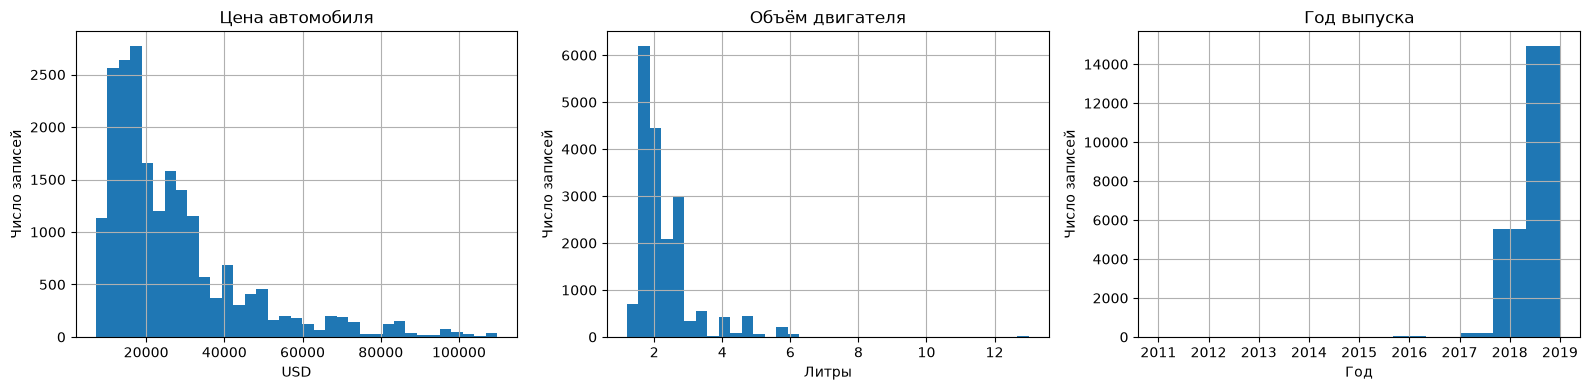

In [19]:
# Числовая сводка: количество известных значений, среднее, медиана
# и процентили. Она помогает оценить диапазон и распределение данных.
display(
    market[["unit_price_usd", "engine_volume_l", "production_year"]]
    .describe(percentiles=[.25, .5, .75, .95, .99])
)

# Создаём область для трёх графиков в одной строке.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Первый график — распределение цен.
# Для наглядности показываем цены до 99-го процентиля.
# Из market дорогие автомобили при этом не удаляются.
price = market["unit_price_usd"]
price[price <= price.quantile(.99)].hist(bins=35, ax=axes[0])
axes[0].set(
    title="Цена автомобиля",
    xlabel="USD",
    ylabel="Число записей"
)

# Второй график — объём двигателя.
# Пропуски убираем только из значений, переданных на этот график.
market["engine_volume_l"].dropna().hist(bins=35, ax=axes[1])
axes[1].set(
    title="Объём двигателя",
    xlabel="Литры",
    ylabel="Число записей"
)

# Третий график — год выпуска.
market["production_year"].dropna().hist(bins=12, ax=axes[2])
axes[2].set(
    title="Год выпуска",
    xlabel="Год",
    ylabel="Число записей"
)

# Подбираем оптимальные расстояния между графиками и показываем их.
plt.tight_layout()
plt.show()

#### Вывод

- Медианная цена — 20 700 USD; распределение имеет правый хвост.
- Медианный объём двигателя — 2,0 л.
- Среди известных годов выпуска преобладают 2018 и 2019.
- Гистограммы построены по строкам таблицы: каждая строка учитывается один раз, даже если в ней продано несколько автомобилей.

### 3.2. Бренды, модели и регионы

Для сравнения брендов, моделей и регионов считаем количество проданных автомобилей по столбцу `quantity`. Число строк для этого не подходит: одна запись может содержать несколько машин. Сначала посмотрим десять крупнейших групп в таблицах, затем покажем бренды и регионы на графиках.

In [20]:
# Считаем, сколько автомобилей продано каждым брендом.
# Сортируем результат так, чтобы первым оказался бренд с наибольшими продажами.
brand_units = (
    market.groupby("brand")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Для моделей группируем сразу по двум столбцам.
# Так модели с одинаковыми названиями у разных брендов не смешаются.
model_units = (
    market.groupby(["brand", "model"])["quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Считаем продажи по регионам.
region_units = (
    market.groupby("region")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Показываем по десять крупнейших брендов, моделей и регионов.
print("Бренды:")
display(brand_units.head(10))

print("Модели:")
display(model_units.head(10))

print("Регионы:")
display(region_units.head(10))

Бренды:


brand
Lada          11085.0
Hyundai        4987.0
Toyota         3636.0
Kia            2346.0
Nissan         1651.0
GAZ            1361.0
UAZ            1217.0
Renault        1193.0
Volkswagen     1048.0
Skoda           776.0
Name: quantity, dtype: float64

Модели:


brand       model 
Lada        Granta    3663.0
            Vesta     2650.0
            4x4       2469.0
            Largus    1682.0
Hyundai     Tucson    1370.0
            Accent    1246.0
Toyota      Camry     1120.0
Hyundai     Creta     1054.0
Kia         Rio        993.0
Volkswagen  Polo       791.0
Name: quantity, dtype: float64

Регионы:


region
Алматы              7682.0
Нур-Султан          5682.0
Атырау              2503.0
Караганда           2355.0
Шымкент             2318.0
Костанай            2212.0
Усть-Каменогорск    1865.0
Уральск             1743.0
Актобе              1422.0
Актау               1400.0
Name: quantity, dtype: float64

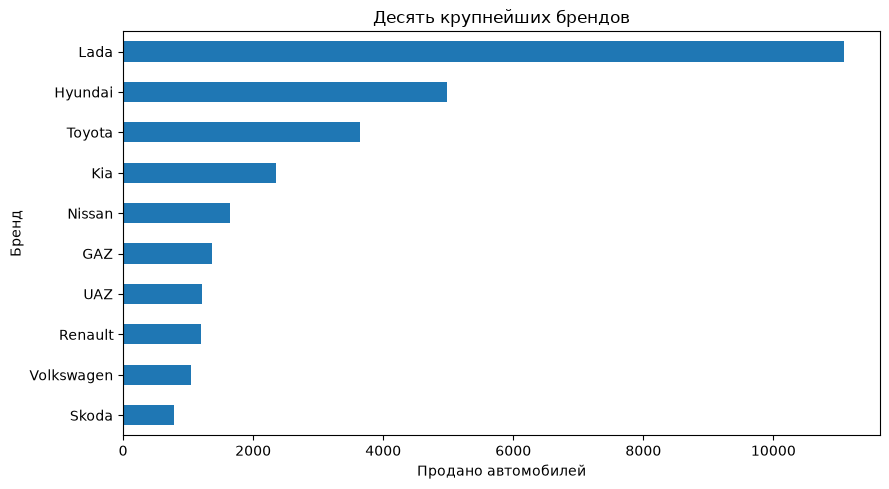

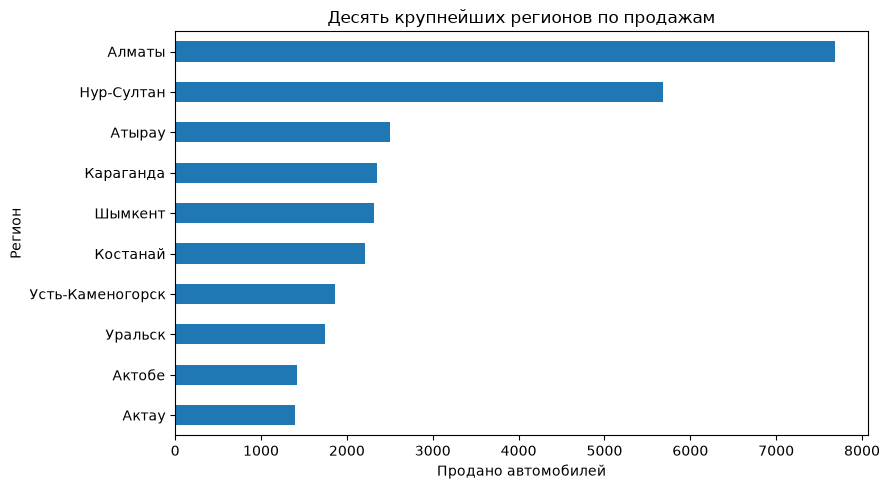

In [21]:
# На первом графике показываем десять брендов с наибольшими продажами.
# sort_values() здесь располагает меньшие столбики снизу,
# а самый большой — сверху горизонтального графика.
ax = brand_units.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title("Десять крупнейших брендов")
ax.set_xlabel("Продано автомобилей")
ax.set_ylabel("Бренд")

plt.tight_layout()
plt.show()


# На втором графике таким же образом показываем регионы.
ax = region_units.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title("Десять крупнейших регионов по продажам")
ax.set_xlabel("Продано автомобилей")
ax.set_ylabel("Регион")

plt.tight_layout()
plt.show()

#### Вывод

- По количеству проданных автомобилей лидируют *Lada — 11 085*, *Hyundai — 4 987* и *Toyota — 3 636*. Таким образом, продажи распределены между брендами неравномерно.
- Среди отдельных моделей первые места занимают *Lada Granta — 3 663*, *Lada Vesta — 2 650* и *Lada 4x4 — 2 469* автомобилей.
- Наибольшее число автомобилей продано в *Алматы — 7 682* и *Нур-Султане — 5 682*. График показывает абсолютный объём продаж, а не долю жителей региона, купивших автомобиль.
- По этим данным можно определить лидеров продаж, но нельзя объяснить различия между регионами только спросом покупателей: на объём также может влиять присутствие дилеров. Для такого объяснения понадобились бы дополнительные данные.

### 3.3. Топливо, коробка передач и сегменты

Сравним продажи автомобилей по виду топлива, коробке передач и сегменту. Количество автомобилей посчитаем по столбцу `quantity`. Отдельно проверим пропуски: если вид топлива или коробка не указаны, такие автомобили не попадут в соответствующую группу, хотя останутся в общем объёме рынка.

In [22]:
# Считаем проданные автомобили по каждому виду топлива.
fuel_units = (
    market.groupby("fuel_type", observed=True)["quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Считаем проданные автомобили по типу коробки передач.
transmission_units = (
    market.groupby("transmission", observed=True)["quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Считаем проданные автомобили по сегментам.
segment_units = (
    market.groupby("segment_2013", observed=True)["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print("Виды топлива:")
display(fuel_units)
print("Строк без указания топлива:", market["fuel_type"].isna().sum())

print("\nКоробки передач:")
display(transmission_units)
print("Строк без указания коробки:", market["transmission"].isna().sum())

print("\nСегменты:")
display(segment_units)
print("Строк без указания сегмента:", market["segment_2013"].isna().sum())

Виды топлива:


fuel_type
F      30822.0
D        903.0
HYB       10.0
E          4.0
Name: quantity, dtype: float64

Строк без указания топлива: 1850

Коробки передач:


transmission
Автомат     16962.0
Механика    14772.0
Name: quantity, dtype: float64

Строк без указания коробки: 1856

Сегменты:


segment_2013
Легковые автомобили        15008.0
Внедорожники               14047.0
Коммерческие автомобили     3487.0
Минивэны                    1798.0
Пикапы                       385.0
Name: quantity, dtype: float64

Строк без указания сегмента: 0


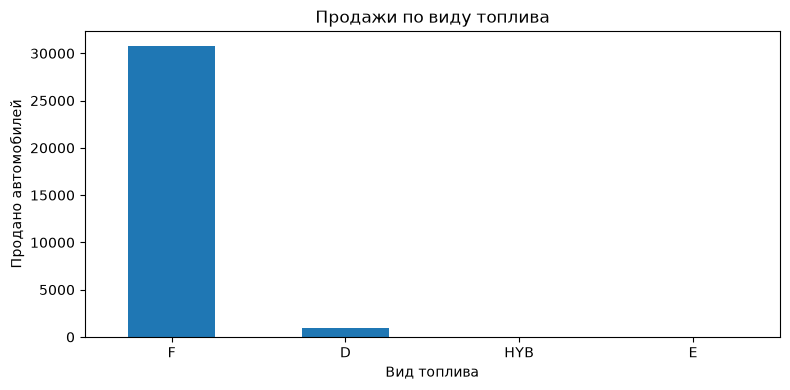

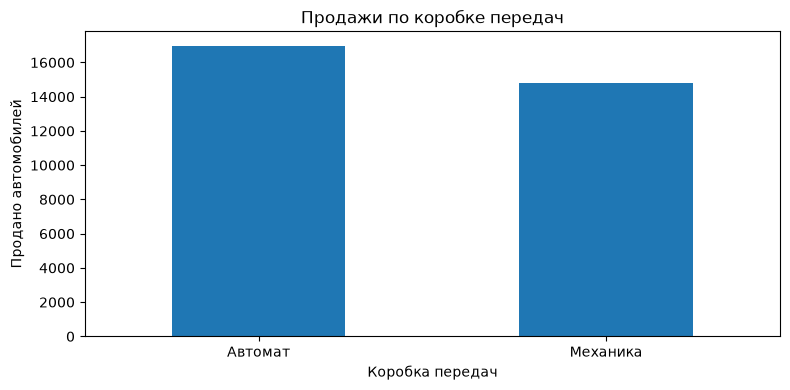

In [23]:
# Показываем, сколько автомобилей продано с каждым известным видом топлива.
ax = fuel_units.plot(kind="bar", figsize=(8, 4))
ax.set_title("Продажи по виду топлива")
ax.set_xlabel("Вид топлива")
ax.set_ylabel("Продано автомобилей")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Сравниваем продажи автомобилей с автоматической и механической коробкой.
ax = transmission_units.plot(kind="bar", figsize=(8, 4))
ax.set_title("Продажи по коробке передач")
ax.set_xlabel("Коробка передач")
ax.set_ylabel("Продано автомобилей")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Вывод

- Среди автомобилей с известным видом топлива преобладают бензиновые. Дизельных автомобилей значительно меньше; электрические и гибридные встречаются редко.
- По известным значениям коробки передач сравним продажи автомобилей с автоматической и механической коробкой. Среди автомобилей с известным типом коробки передач автоматическая встречается чаще механической: 16 962 против 14 772 автомобилей.
- Самые крупные сегменты по количеству проданных автомобилей — легковые автомобили и внедорожники.
- В столбцах с видом топлива и коробкой передач есть пропуски. Поэтому графики показывают распределение только среди автомобилей, для которых соответствующий признак известен. По ним нельзя без оговорки определить долю каждого типа среди всех продаж.

### 3.4. Динамика продаж

Посмотрим, как менялось количество проданных автомобилей с января по сентябрь 2019 года. Сгруппируем продажи по месяцам и для каждого месяца сложим значения `quantity`. Дата на графике обозначает месяц учёта: последний день месяца выбран условно, поскольку точный день каждой продажи в исходных данных неизвестен.

sale_date
2019-01-31    2953.0
2019-02-28    3193.0
2019-03-31    3437.0
2019-04-30    4282.0
2019-05-31    4257.0
2019-06-30    4177.0
2019-07-31    4432.0
2019-08-31    4250.0
2019-09-30    3744.0
Name: quantity, dtype: float64

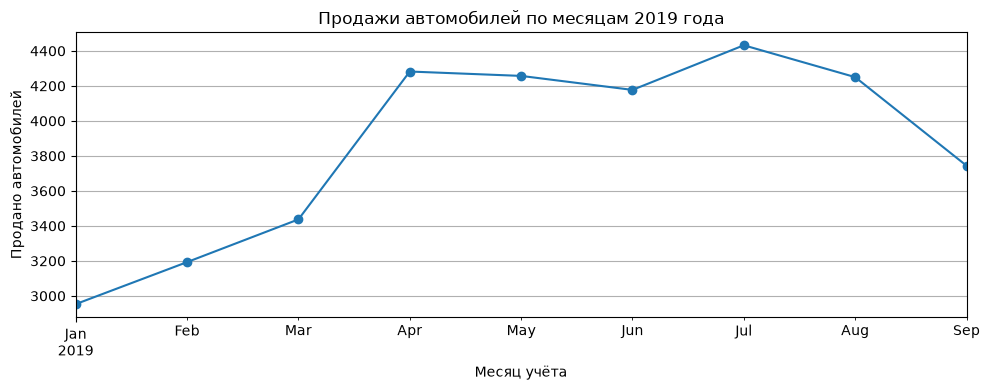

In [24]:
# Складываем количество автомобилей по каждому месяцу.
# sort_index() располагает даты в календарном порядке.
monthly = (
    market.groupby("sale_date")["quantity"]
    .sum()
    .sort_index()
)

# Сначала смотрим точные значения, по которым построим график.
display(monthly)


# Строим линию, чтобы увидеть изменение продаж от месяца к месяцу.
# Точки показывают значения отдельных месяцев.
ax = monthly.plot(
    marker="o",
    figsize=(10, 4),
    grid=True
)

ax.set_title("Продажи автомобилей по месяцам 2019 года")
ax.set_xlabel("Месяц учёта")
ax.set_ylabel("Продано автомобилей")

plt.tight_layout()
plt.show()

#### Вывод

- В январе продано 2 953 автомобиля, в июле — 4 432. Таким образом, к июлю месячный объём продаж стал выше, хотя рост не был непрерывным: между отдельными месяцами встречались небольшие снижения.
- После июля продажи снизились; в сентябре продано 3 744 автомобиля.
- Мы видим динамику только за январь–сентябрь 2019 года. По девяти месяцам одного года нельзя уверенно судить о ежегодной сезонности или о результатах всего 2019 года.

## 4. Положение «Меркур Авто»

Сравним продажи «Меркур Авто» со всем внутренним рынком по количеству автомобилей и выручке. Затем рассчитаем среднюю выручку на один автомобиль и долю автоцентра в продажах рынка. При расчёте количества используем столбец `quantity`, поскольку одна строка может содержать несколько машин.

In [25]:
# Считаем количество проданных автомобилей на всём рынке
# и отдельно у «Меркур Авто».
market_units = market["quantity"].sum()
mercur_units = mercur["quantity"].sum()

# Так же считаем выручку по итоговой стоимости продаж.
market_sales = market["total_sales_usd"].sum()
mercur_sales = mercur["total_sales_usd"].sum()

# Средняя выручка на автомобиль — это общая выручка,
# разделённая на число проданных автомобилей.
market_per_car = market_sales / market_units
mercur_per_car = mercur_sales / mercur_units

# Собираем показатели рядом, чтобы их было удобно сравнивать.
kpi = pd.DataFrame(
    {
        "Рынок": [market_units, market_sales, market_per_car],
        "Меркур Авто": [mercur_units, mercur_sales, mercur_per_car],
    },
    index=[
        "Продано автомобилей",
        "Выручка, USD",
        "Средняя выручка на автомобиль, USD",
    ],
)

display(kpi.style.format("{:,.2f}", thousands=" ", decimal=","))

,Рынок,Меркур Авто
Продано автомобилей,"34 725,00","394,00"
"Выручка, USD","801 697 865,97","15 121 529,04"
"Средняя выручка на автомобиль, USD","23 087,05","38 379,52"


In [26]:
# Доля по количеству: какую часть всех проданных машин
# продал «Меркур Авто».
unit_share = 100 * mercur_units / market_units

# Доля по выручке: какую часть выручки рынка
# получили продажи «Меркур Авто».
sales_share = 100 * mercur_sales / market_sales

print("Доля «Меркур Авто» по автомобилям, %:", round(unit_share, 2))
print("Доля «Меркур Авто» по выручке, %:", round(sales_share, 2))

Доля «Меркур Авто» по автомобилям, %: 1.13
Доля «Меркур Авто» по выручке, %: 1.89


### 4.1. Бренды автоцентра

Сравним продажи брендов, представленных у «Меркур Авто», с общими продажами этих брендов на внутреннем рынке. Для каждого бренда рассчитаем долю автоцентра по количеству автомобилей. Затем посмотрим на структуру продаж самого автоцентра.

In [27]:
# Считаем продажи каждого бренда у «Меркур Авто».
mercur_brands = (
    mercur.groupby("brand")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Считаем продажи тех же и остальных брендов на всём рынке.
market_brands = market.groupby("brand")["quantity"].sum()

# Ставим результаты рядом. Для брендов, которых нет у автоцентра,
# вместо пропуска будет 0 проданных им автомобилей.
brand_compare = pd.DataFrame({
    "Продано на рынке": market_brands,
    "Продано в Меркур Авто": mercur_brands,
}).fillna(0)

# Вычисляем долю автоцентра в продажах каждого бренда.
brand_compare["Доля Меркур Авто, %"] = (
    100 * brand_compare["Продано в Меркур Авто"]
    / brand_compare["Продано на рынке"]
)

# Показываем только бренды, которые продаёт «Меркур Авто».
display(brand_compare.loc[mercur_brands.index].round(2))

,Продано на рынке,Продано в Меркур Авто,"Доля Меркур Авто, %"
brand,,,
Volkswagen,1048.0,294.0,28.05
Porsche,52.0,52.0,100.00
Audi,48.0,48.0,100.00


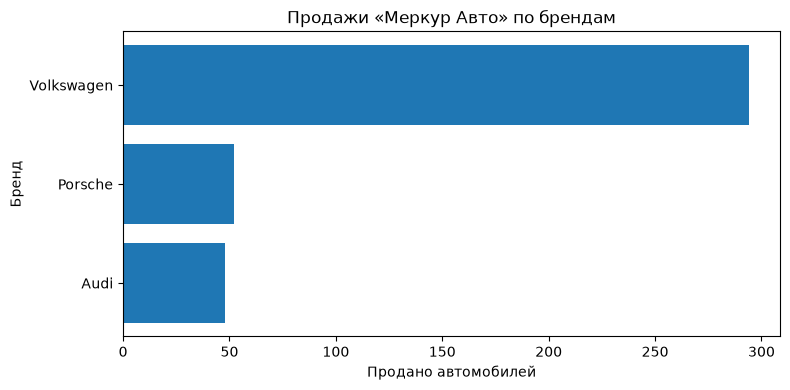

In [28]:
# Для горизонтального графика располагаем бренды
# от меньшего числа проданных машин к большему.
ordered_brands = mercur_brands.sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ordered_brands.index, ordered_brands.values)

ax.set_title("Продажи «Меркур Авто» по брендам")
ax.set_xlabel("Продано автомобилей")
ax.set_ylabel("Бренд")

plt.tight_layout()
plt.show()

#### Вывод

- В продажах «Меркур Авто» преобладает *Volkswagen*: 294 из 394 автомобилей. Также проданы 52 автомобиля Porsche и 48 автомобилей Audi. Таким образом, продажи автоцентра сосредоточены в трёх брендах.
- Доля «Меркур Авто» среди продаж Volkswagen в исследуемых данных составляет около *28,05%*.
- Для Porsche и Audi таблица показывает долю *100%*: в данной выгрузке их продажи относятся к «Меркур Авто». Это не означает, что автоцентр был единственным продавцом этих брендов во всём Казахстане: вывод ограничен составом предоставленных данных.

### 4.2. Регионы и сегменты

Сравним положение «Меркур Авто» в регионах и сегментах. Сначала рассчитаем, какую часть продаж каждой группы обеспечил автоцентр. Затем сравним структуру продаж: какую долю занимают разные сегменты на всём рынке и внутри самого автоцентра. Это два разных показателя, поэтому рассмотрим их отдельно.

In [29]:
# Считаем количество проданных автомобилей в каждом регионе
# на всём внутреннем рынке и отдельно у «Меркур Авто».
market_regions = market.groupby("region")["quantity"].sum()
mercur_regions = mercur.groupby("region")["quantity"].sum()

# Соединяем оба результата в одну таблицу.
# Если у автоцентра нет продаж в регионе, ставим 0.
region_compare = pd.DataFrame({
    "Рынок, автомобилей": market_regions,
    "Меркур Авто, автомобилей": mercur_regions,
}).fillna(0)

# Для каждого региона считаем долю автоцентра
# среди всех проданных в этом регионе автомобилей.
region_compare["Доля Меркур Авто, %"] = (
    100 * region_compare["Меркур Авто, автомобилей"]
    / region_compare["Рынок, автомобилей"]
)

# Сначала показываем регионы, где автоцентр продал больше машин.
display(
    region_compare
    .sort_values("Меркур Авто, автомобилей", ascending=False)
    .round(2)
)

,"Рынок, автомобилей","Меркур Авто, автомобилей","Доля Меркур Авто, %"
region,,,
Алматы,7682.0,251.0,3.27
Нур-Султан,5682.0,51.0,0.90
Атырау,2503.0,43.0,1.72
Караганда,2355.0,21.0,0.89
Уральск,1743.0,14.0,0.80
Костанай,2212.0,14.0,0.63
Актау,1400.0,0.0,0.00
Рудный,21.0,0.0,0.00
Шымкент,2318.0,0.0,0.00


In [30]:
# Повторяем сравнение, но теперь по сегментам автомобилей.
market_segments = (
    market.groupby("segment_2013", observed=True)["quantity"].sum()
)
mercur_segments = (
    mercur.groupby("segment_2013", observed=True)["quantity"].sum()
)

segment_compare = pd.DataFrame({
    "Рынок, автомобилей": market_segments,
    "Меркур Авто, автомобилей": mercur_segments,
}).fillna(0)

# Делим продажи автоцентра в сегменте на все продажи
# этого сегмента на рынке.
segment_compare["Доля Меркур Авто, %"] = (
    100 * segment_compare["Меркур Авто, автомобилей"]
    / segment_compare["Рынок, автомобилей"]
)

display(
    segment_compare
    .sort_values("Меркур Авто, автомобилей", ascending=False)
    .round(2)
)

,"Рынок, автомобилей","Меркур Авто, автомобилей","Доля Меркур Авто, %"
segment_2013,,,
Легковые автомобили,15008.0,234.0,1.56
Внедорожники,14047.0,145.0,1.03
Коммерческие автомобили,3487.0,8.0,0.23
Минивэны,1798.0,5.0,0.28
Пикапы,385.0,2.0,0.52


,"Рынок, %","Меркур Авто, %"
segment_2013,,
Внедорожники,40.5,36.8
Коммерческие автомобили,10.0,2.0
Легковые автомобили,43.2,59.4
Минивэны,5.2,1.3
Пикапы,1.1,0.5


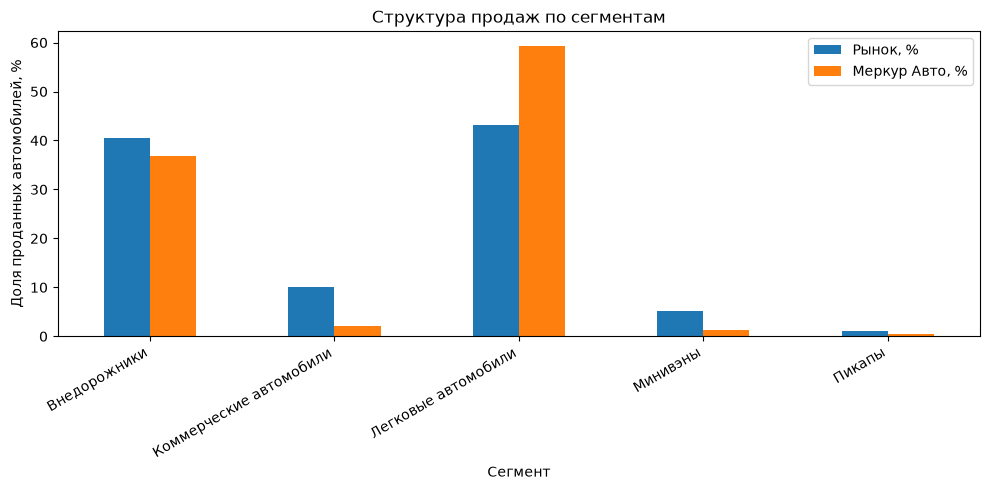

In [31]:
# Теперь знаменатель другой: все машины рынка или все машины автоцентра.
# Поэтому эти проценты показывают структуру продаж, а не долю
# «Меркур Авто» среди продавцов сегмента.
structure = pd.DataFrame({
    "Рынок, %": 100 * market_segments / market_units,
    "Меркур Авто, %": 100 * mercur_segments / mercur_units,
}).fillna(0)

display(structure.round(1))

# Рисуем доли сегментов на рынке и в автоцентре рядом.
ax = structure.plot(kind="bar", figsize=(10, 5))

ax.set_title("Структура продаж по сегментам")
ax.set_xlabel("Сегмент")
ax.set_ylabel("Доля проданных автомобилей, %")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Вывод

- Больше всего автомобилей «Меркур Авто» продал в *Алматы — 251 из 394*. Продажи также есть в Нур-Султане, Атырау и нескольких других регионах. Это показывает, что продажи автоцентра сосредоточены прежде всего в Алматы.
- В Алматы доля автоцентра среди проданных автомобилей составляет около *3,27%*. Этот показатель не следует путать с долей Алматы *в продажах самого автоцентра*: у них разные знаменатели.
- По количеству автомобилей для «Меркур Авто» важнее всего легковой сегмент и внедорожники. В легковом сегменте доля центра на рынке составляет около *1,56%*, во внедорожниках — около *1,03%*. В коммерческом сегменте она заметно ниже.
- Сравнение структуры продаж показывает, какие сегменты представлены у автоцентра сильнее или слабее, чем на рынке в целом. Различия описывают состав продаж; сами по себе они не доказывают, почему покупатели выбирают определённые автомобили.

## 5. Общий вывод

- Данные о продажах автомобилей в Казахстане за январь–сентябрь 2019 года были загружены и подготовлены к дальнейшему анализу. Исходный файл имел 39 966 строк и 25 столбцов. После удаления 18 698 полностью совпадающих строк и семи неиспользуемых столбцов итоговая таблица содержит 21 268 строк и 17 столбцов. Очищенные данные сохранены в отдельном CSV-файле; исходный файл при этом сохранён.

- В ходе подготовки мы привели к единому виду названия стран, виды топлива, типы привода, коробки передач и названия компаний. Объём двигателя, количество автомобилей и денежные показатели переведены в числовой формат; из года и месяца создана дата учёта с последним днём месяца. Мы проверили необычные значения отдельно: запись о мощности Jaguar не приняли за литраж, ошибки у Chevrolet Niva исправили, а неправдоподобный объём 8,7 л у Volkswagen Polo оставили пропущенным, поскольку точное значение установить нельзя. Возврат и крупные заказы сохранили как возможные реальные операции.

- Для анализа внутреннего рынка мы исключили записи с регионом «Экспорт» только из расчётов рыночных показателей. За рассматриваемые девять месяцев на внутреннем рынке отражена продажа 34 725 автомобилей. Медианная цена автомобиля составляет 20 700 USD, медианный объём двигателя — 2,0 л. Среди автомобилей с известным годом выпуска преобладают машины 2018 и 2019 годов. Наибольшие продажи по количеству автомобилей приходятся на Lada, Hyundai и Toyota; среди регионов лидируют Алматы и Нур-Султан.

- В структуре продаж преобладают автомобили с бензиновым двигателем. Среди записей, где указан тип коробки передач, автомобилей с автоматической коробкой продано больше, чем с механической: 16 962 против 14 772. Крупнейшие группы по сегменту — легковые автомобили и внедорожники. Поскольку часть записей не содержит сведений о топливе или коробке передач, соответствующие соотношения описывают только автомобили с известными значениями этих признаков.

- Месячный объём продаж вырос с 2 953 автомобилей в январе до 4 432 в июле, но рост не был непрерывным. После июльского максимума продажи снизились до 3 744 автомобилей в сентябре. Данные охватывают только девять месяцев одного года, поэтому по ним нельзя делать уверенный вывод о сезонности или результатах всего 2019 года.

- «Меркур Авто» продал 394 автомобиля. Его доля во внутреннем рынке составляет около 1,13% по числу автомобилей и 1,89% по выручке. Средняя выручка на один проданный автомобиль у автоцентра — около 38 380 USD против 23 087 USD на рынке в целом. Более высокая доля по выручке согласуется с тем, что в продажах автоцентра представлены сравнительно дорогие автомобили.

- Основу продаж «Меркур Авто» составляют Volkswagen: 294 автомобиля из 394. Далее следуют Porsche — 52 и Audi — 48. Больше всего автомобилей центр продал в Алматы — 251; его доля среди продаж этого города составляет около 3,27%. В структуре автоцентра легковые автомобили занимают большую долю, чем на рынке в целом: 59,4% против 43,2%. Это показывает сильную позицию в представленном ассортименте, но также указывает на зависимость результатов от небольшого числа брендов и значительную концентрацию продаж в Алматы.

- Результаты следует рассматривать с учётом ограничений данных. В исходном файле нет идентификатора сделки, поэтому нельзя достоверно установить, были ли все полностью одинаковые строки ошибочными повторами или отдельными одинаковыми продажами. Неизвестные значения отдельных признаков мы не заменяли догадками. Полученные показатели описывают предоставленную выгрузку за январь–сентябрь 2019 года и служат основанием для дальнейшей проверки спроса, ассортимента и возможностей роста «Меркур Авто», а не готовым решением об изменении бизнеса.